# Nuclear Power Reactors Output Power Data

We will use this script to get the power output data for each of the 94 operating nuclear power reactors from 2000 - 2025 from the [Nuclear Regulatory Commision](https://www.nrc.gov/documents-reports/document-collections/events-reports-associated-with/power-reactor-status-reports/)

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from pathlib import Path

# This library helps us to visualize the progress of our data download
from tqdm.auto import tqdm

# Multi Threading
from concurrent.futures import ThreadPoolExecutor
import time

In [3]:
import threading

thread_local = threading.local()

# requests.get() sets up a new connection every time with the NRC website
# Howeveer there is a way to just start a session and keep working in that via requests.Session()
# Another way to make this process fatser is using ThreadPoolExecutor so there are mutliple threads working paralleley 
# But in that case we need a define a seperate session for each working thread 

def get_session():
    # The first time a thread calls this, it has no session yet, so make one.
    # Every later call from that same thread reuses it.
    if not hasattr(thread_local, "session"):
        thread_local.session = requests.Session()
    return thread_local.session

outdir = Path("/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data/daily_reports/")
outdir.mkdir(exist_ok=True)

URL="https://www.nrc.gov/documents-reports/document-collections/events-reports-associated-with/power-reactor-status-reports/"

def get_daily_data(date):

    Full_URL = URL + f'{date.year}/{date:%Y%m%d}ps'

    for attempt in range(3):
        
        webpage = get_session().get(Full_URL, timeout=60)
        if webpage.ok:
            break
        time.sleep(30)
    
    if not webpage.ok:
        print("Could not fetch data for", date.date())
        return None

    time.sleep(0.25)
    
    soup = BeautifulSoup(webpage.content, "html.parser")
    rows = []
    
    for table in soup.find_all("table"):

        # Each table sits right after a heading like <h3>Region 1</h3>
        heading = table.find_previous("h3")
        region = heading.get_text(strip=True) if heading else None

        for row in table.find_all("tr"):
    
            # Unit, Power, Down, Reason, Change in report, Scrams
            cells = [ td.get_text(strip=True) for td in row.find_all("td") ]
            if len(cells) != 6:
                continue
            rows.append({"date": date, "Region": region, "Unit": cells[0], "Power": cells[1], "Down": cells[2], "Reason": cells[3]})

    return rows

# An empty list to hold the names of the yearly csv files with daily reports
report_list = []

# The start is inclusive but stop is excluded
for year in range(2000, 2026):

    outfile = outdir / f'{year}DailyReports.csv'

    if not outfile.exists():

        dates = pd.date_range(f'{year}-01-01', f'{year}-12-31')
        year_rows = []

        # get_daily_data returns a list of dicts [dict1, dict2 , ...]
        # daily_rows would be a list of list -- > [ [dict1, dict2], [dict3, dict4] ]
        with ThreadPoolExecutor(max_workers=2) as pool:
            daily_rows = list( tqdm(pool.map(get_daily_data, dates), total=len(dates), desc=str(year)))

        failed = sum(rows is None for rows in daily_rows)
        if failed > 0:
            print(f'{year}: {failed} days failed, not saving. Rerun this cell later.')
            continue

        # This will basically give you [ dict1, dict2, dict3, dict4 ]
        for rows in daily_rows:
            year_rows.extend(rows)

        pd.DataFrame(year_rows).to_csv(outfile, index=False)

    report_list.append(pd.read_csv(outfile, parse_dates=["date"])) # Read the date column as a date not a text

df = pd.concat(report_list, ignore_index=True)  
print(df.head())

        date    Region              Unit  Power Down  \
0 2000-01-01  Region 1   Beaver Valley 1    100  NaN   
1 2000-01-01  Region 1   Beaver Valley 2     51  NaN   
2 2000-01-01  Region 1  Calvert Cliffs 1    100  NaN   
3 2000-01-01  Region 1  Calvert Cliffs 2     65  NaN   
4 2000-01-01  Region 1       FitzPatrick     80  NaN   

                         Reason  
0                           NaN  
1             FUEL CONSERVATION  
2                           NaN  
3  Y2K TRANSITION PLANNED POWER  
4  Y2K TRANSITION PLANNED POWER  


In [4]:
print("From the daily reports spanning 2000-2025 we have", df["Unit"].nunique(), "recators.")
print("Number of rows in the dataframe", len(df))

From the daily reports spanning 2000-2025 we have 110 recators.
Number of rows in the dataframe 954906


### Cleaning the power data

The daily power files for 2000–2025 contain **110 different reactors**, but
`get_reactor_list.ipynb` found only **94 currently operating** reactors. The
difference comes from reactors that have shut down since 2005.

Before analysis, the data needs some cleaning:

1. **Keep only operating reactors.** Drop the reactors that are not in the reactor list from `get_reactor_list.ipynb`.
2. **Match reactor names.** The two NRC sources spell some names differently (e.g. `Arkansas Nuclear 1` in the power data vs `Arkansas Nuclear One 1` in the reactor list), so these names must be made consistent before joining.

                          min        max  count
Unit                                           
Arkansas Nuclear 1 2000-01-01 2025-12-31   9493
Arkansas Nuclear 2 2000-01-01 2025-12-31   9493
Beaver Valley 1    2000-01-01 2025-12-31   9493
Beaver Valley 2    2000-01-01 2025-12-31   9493
Braidwood 1        2000-01-01 2025-12-31   9493


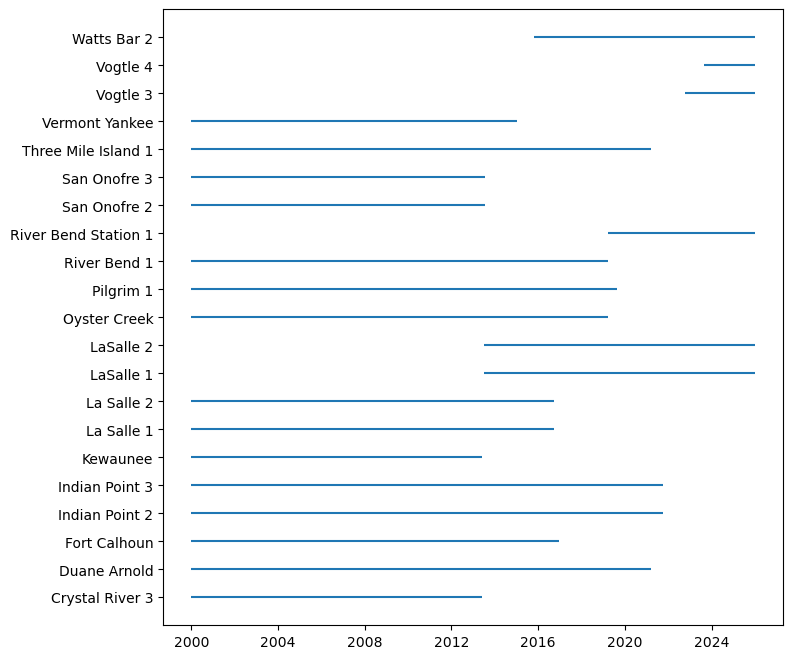

In [5]:
runtime_df = df.groupby("Unit")["date"].agg(["min", "max", "count"])
print(runtime_df.head())

runtime_filtered_df = runtime_df[ (runtime_df["min"] > "2000-01-01") | (runtime_df["max"] < "2025-12-31")]

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(8,8))
plt.hlines(y=runtime_filtered_df.index, xmin=runtime_filtered_df["min"], xmax=runtime_filtered_df["max"])
plt.show()


As can be seen in the above plot, 12 nuclear power reactors are not currently operating. We would drop the data from these reactors.

**We need to rename some units to have naming consistency**
1. La Salle 1 --> LaSelle 1
2. La Selle 2 --> LaSelle 2
3. River Bend 1 --> River Bend Station 1

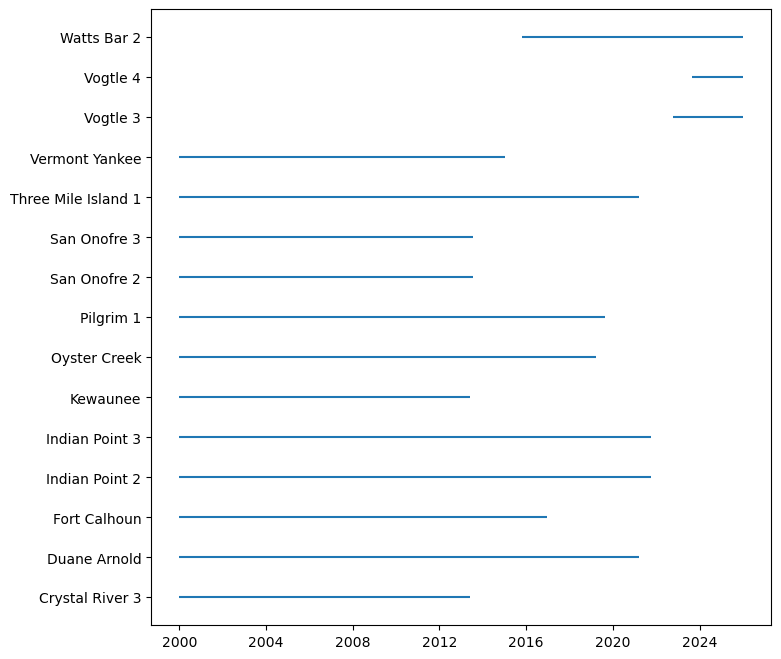

In [6]:
df["Unit"] = df["Unit"].replace({ "LaSalle 1": "La Salle 1", "LaSalle 2": "La Salle 2", "River Bend Station 1": "River Bend 1" })
runtime_df = df.groupby("Unit")["date"].agg(["min", "max", "count"])
runtime_filtered_df = runtime_df[ (runtime_df["min"] > "2000-01-01" ) | (runtime_df["max"] < "2025-12-31") ]

plt.figure(figsize=(8,8))
plt.hlines(y=runtime_filtered_df.index, xmin=runtime_filtered_df["min"], xmax=runtime_filtered_df["max"])
plt.show()

In [7]:
unoperating_reactors = runtime_filtered_df[ runtime_filtered_df["max"] < "2025-12-31" ].index

In [8]:
new_df = df.drop(df[ df["Unit"].isin(unoperating_reactors) ].index).reset_index(drop=True)
print(new_df.head())
print("Number of rows and columns", new_df.shape)

print("After removing currently unoperating reactors, we now have", new_df["Unit"].nunique(), "reactors")

        date    Region              Unit  Power Down  \
0 2000-01-01  Region 1   Beaver Valley 1    100  NaN   
1 2000-01-01  Region 1   Beaver Valley 2     51  NaN   
2 2000-01-01  Region 1  Calvert Cliffs 1    100  NaN   
3 2000-01-01  Region 1  Calvert Cliffs 2     65  NaN   
4 2000-01-01  Region 1       FitzPatrick     80  NaN   

                         Reason  
0                           NaN  
1             FUEL CONSERVATION  
2                           NaN  
3  Y2K TRANSITION PLANNED POWER  
4  Y2K TRANSITION PLANNED POWER  
Number of rows and columns (877939, 6)
After removing currently unoperating reactors, we now have 95 reactors


As can be seen we still have one extra reactor relative to the currently operating reactors list. Let's find out which one is that

In [9]:

currently_operating_reactors = "/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data/reactor_list.csv"
currently_operating_reactors_df = pd.read_csv(currently_operating_reactors)
print(currently_operating_reactors_df.columns)

a = set(currently_operating_reactors_df["name"])
b = set(new_df["Unit"])

print("The reactors in the currently operating list that are not in the analyzed dataframe from daily reports", a-b)
print("The reactors in the analyzed dataframe from daily reports but not in the currently operating list", b-a)


Index(['code', 'name', 'Region', 'State'], dtype='str')
The reactors in the currently operating list that are not in the analyzed dataframe from daily reports {'Arkansas Nuclear One 1', 'V.C. Summer', 'Arkansas Nuclear One 2'}
The reactors in the analyzed dataframe from daily reports but not in the currently operating list {'Summer', 'Arkansas Nuclear 2', 'Arkansas Nuclear 1', 'Palisades'}


We can see that there are 3 naming mismatches and one reactor `Palisades` just not there in the currently operating list

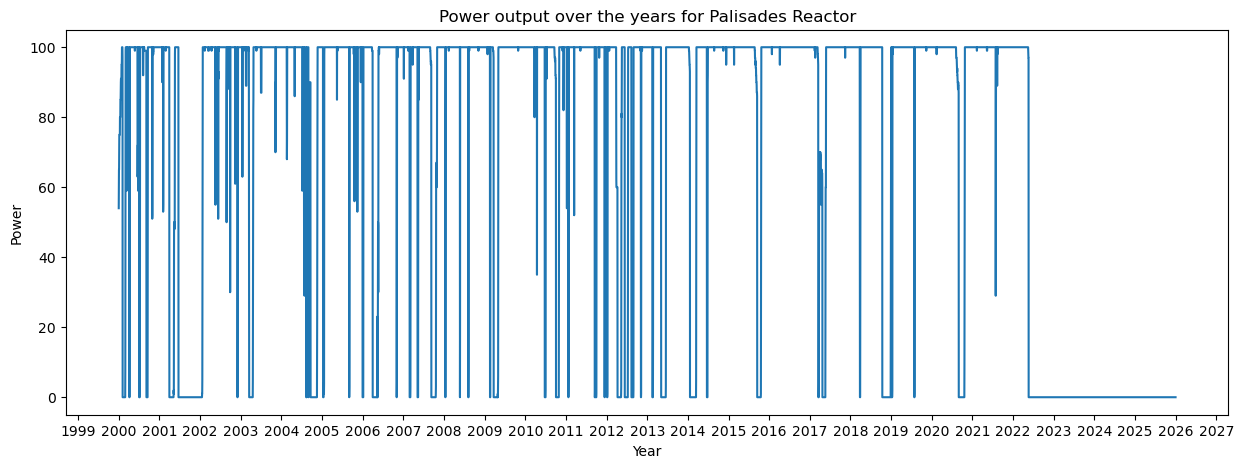

In [10]:
new_df["Unit"] = new_df["Unit"].replace({"Arkansas Nuclear 1": "Arkansas Nuclear One 1", "Arkansas Nuclear 2": "Arkansas Nuclear One 2", "Summer": "V.C. Summer"})

plt.figure(figsize=(15,5))
plt.plot(new_df[new_df["Unit"] == "Palisades"].date, new_df[new_df["Unit"] == "Palisades"].Power)
plt.xlabel("Year")
plt.ylabel("Power")
plt.title("Power output over the years for Palisades Reactor")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator())

As can be seen in the plot above, the reactor did not report any power output data after mid 2022 but there are some data at the end of 2025 which is why it passed our filters above. Nevertheless we can remove it from our analysis as it is indeed not currently operating

In [11]:
new_df = new_df.drop( new_df[new_df["Unit"] == "Palisades"].index ).reset_index(drop=True)
a = set(currently_operating_reactors_df["name"])
b = set(new_df["Unit"])

print("The reactors in the currently operating list that are not in the analyzed dataframe from daily reports", a-b)
print("The reactors in the analyzed dataframe from daily reports but not in the currently operating list", b-a)

print("The number of rows in the dataframe", len(new_df))

The reactors in the currently operating list that are not in the analyzed dataframe from daily reports set()
The reactors in the analyzed dataframe from daily reports but not in the currently operating list set()
The number of rows in the dataframe 869625


Another data cleaning step requires identifying any duplicates in the data. For that we can use the inbuilt `duplicate` fucntion in pandas

In [12]:
new_df.duplicated(keep="first").sum()
print("There are", new_df.duplicated(keep="first").sum(), "duplicates in the data frame")

There are 67 duplicates in the data frame


In [13]:
new_df = new_df.drop_duplicates(subset=["Unit", "date"], keep="first").reset_index(drop=True)
print(new_df.shape)

(869529, 6)


Next thing we want to make sure is that there are no missing days for any reactor. You can see that grouping the df by Unit is the sensible choice here. We will sort the dataframe first by the "Unit" and then by the "date" and finally use the .diff() command (this date minus the previous date), if there are no gaps the only value available would be 1

In [14]:
new_df = new_df.sort_values(["Unit", "date"]).reset_index(drop=True)
new_df["gap"] = new_df.groupby("Unit")["date"].diff().dt.days

gap_rows = new_df[new_df["gap"] > 1]
gap_rows[["date", "gap"]].value_counts()

date        gap
2015-12-05  4.0    92
2013-07-19  2.0    91
2013-12-22  2.0    91
Name: count, dtype: int64

As can be seen more than 90 reactors do not have any data starting these 3 dates. However looking at the yearly power reports it seems like the report is indeed available for these missing reorts but with one caveat that the reason if the power was down from 100% is not listed in those reports.

From the above cells we can see the gap dates are `(2013-07-18), (2013-12-21), (2015-12-04, 2015-12-03, 2015-12-02)`

In [15]:
missing_days = pd.to_datetime(["2013-07-18", "2013-12-21", "2015-12-02", "2015-12-03", "2015-12-04"])
yearly_data = pd.concat([ pd.read_csv(f'/Users/vassu/Desktop/Erdos_DataScience/NuclearReliability/reactor_data/yearly_reports/{year}PowerStatus.txt', sep="|", parse_dates=["ReportDt"]) for year in [2013, 2015] ])

missing_data = yearly_data[ yearly_data["ReportDt"].isin(missing_days) ].sort_values("ReportDt").reset_index(drop=True)
missing_data.head()

,ReportDt,Unit,Power
0,2013-07-18,McGuire 2,100
1,2013-07-18,Dresden 2,100
2,2013-07-18,Dresden 3,100
3,2013-07-18,Duane Arnold,100
4,2013-07-18,Farley 1,100


Before merging these missing days with the main dataframe we need to account for the same naming inconsistencies as we dealt with before and remove the currently not oprating reactors

In [16]:
missing_data["Unit"] = missing_data["Unit"].replace({"LaSalle 1": "La Salle 1", "LaSalle 2": "La Salle 2", "River Bend Station 1": "River Bend 1", "Arkansas Nuclear 1": "Arkansas Nuclear One 1", "Arkansas Nuclear 2": "Arkansas Nuclear One 2", "Summer": "V.C. Summer"})

In [17]:
missing_data = missing_data[missing_data["Unit"].isin(currently_operating_reactors_df["name"])].reset_index(drop=True)

Now before we can merge it with our main dataframe we need to first make it the same structure as our `new_df` for that we need to rename "ReportDt" -- > "date", Add the `Region` column and then define the `Down` and the `Reason` columns. 

In [18]:
import numpy as np

missing_data = missing_data.rename(columns={"ReportDt":"date"})
missing_data["Down"] = np.nan # Matching new_df convention
missing_data["Reason"] = ["Not Available" if p < 100 else np.nan for p in missing_data["Power"]]

# For the region information we need a lookup table between Unit --> Region

unit_region_map = new_df.groupby("Unit")["Region"].first()

missing_data["Region"] = missing_data["Unit"].map(unit_region_map)

missing_data.duplicated(keep="first").sum()

np.int64(0)

In [19]:
new_df = pd.concat([new_df, missing_data], ignore_index=True)
new_df = new_df.sort_values(["Unit", "date"]).reset_index(drop=True)

new_df.groupby("Unit")["date"].diff().dt.days.value_counts()

columns_to_keep = ["date", "Region", "Unit", "Power", "Down", "Reason"]

for year, year_df in new_df.groupby(new_df["date"].dt.year):
    year_df[columns_to_keep].to_csv(outdir/f"CleanedData_{year}.csv", sep="\t", index=False)

**We have accounted for all the missing data**

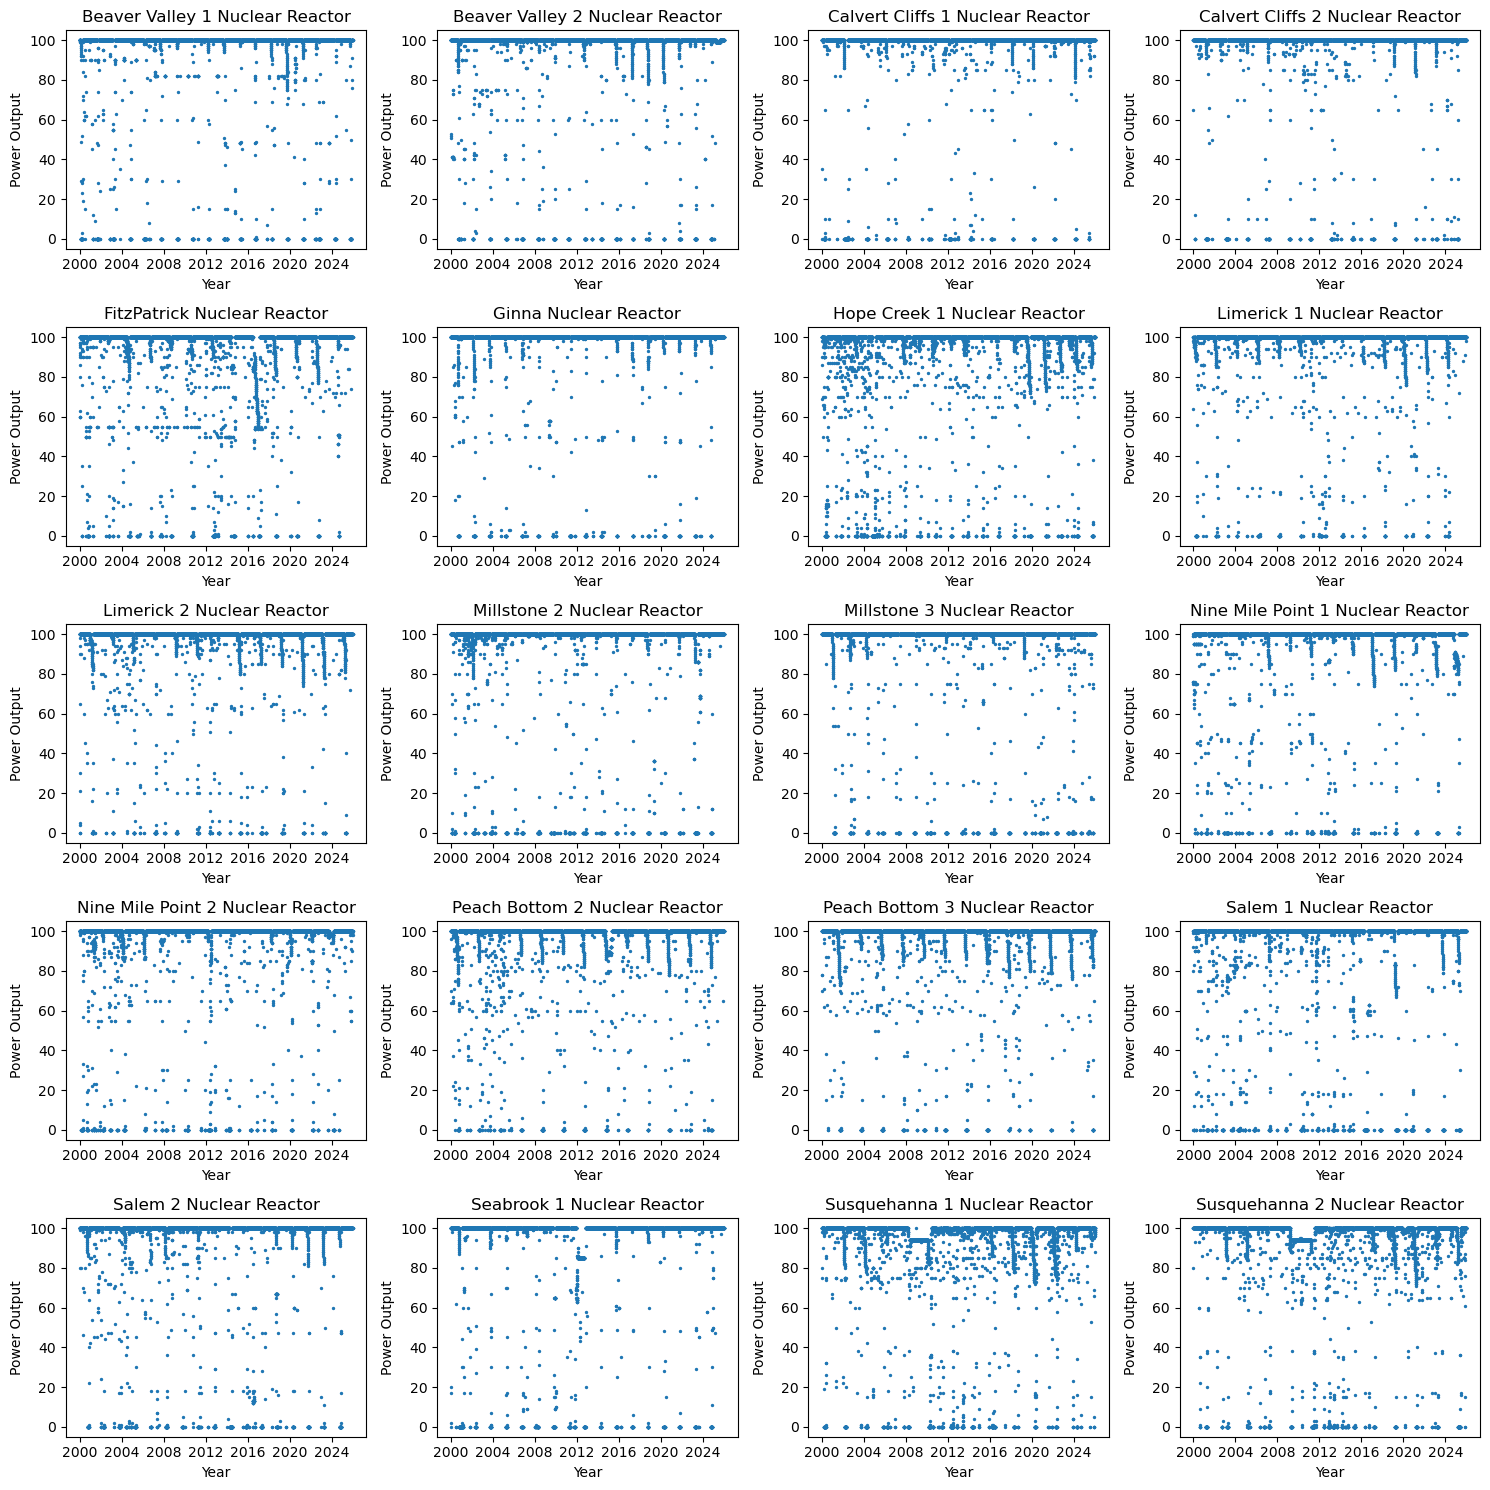

In [20]:
fig, axes = plt.subplots(5,4,figsize=(15,15))
axes = axes.flatten()

region1_reactors = new_df[new_df["Region"] == "Region 1"]
region1_reactor_names = sorted(region1_reactors["Unit"].unique())

for i in range(len(region1_reactor_names)):
    axes[i].scatter(region1_reactors[ region1_reactors["Unit"] == region1_reactor_names[i] ].date, region1_reactors[ region1_reactors["Unit"] == region1_reactor_names[i] ].Power, s=2)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Power Output")
    axes[i].set_title(f'{region1_reactor_names[i]} Nuclear Reactor')

plt.tight_layout()
plt.show()

In [21]:
rows = []

# unit holds the "Unit" name and unit_df holds the dataframe for each unit (The entire dataframe including Unit itself)

for unit, unit_df in new_df.groupby("Unit"):

    region = unit_df["Region"].iloc[0]

    count = 0

    for power, date, reason in zip(unit_df["Power"], unit_df["date"], unit_df["Reason"]):

        if power == 0:
            if count == 0:
                start = date
                outage_reason = np.nan # Initlialize to missing
                refuel_days = 0 # Initialize to 0
            if pd.isna(outage_reason) and pd.notna(reason):
                outage_reason = reason
            if pd.notna(reason) and ("refuel" in reason.lower() or "defuel" in reason.lower()):
                refuel_days += 1
            count += 1
            end = date
        elif count > 0:
            rows.append({ "Unit":unit, "Region": region, "Start_Date": start, "End_Date": end, "Outage_Duration": count, "Reason":outage_reason, "Refuel_Days": refuel_days})
            count = 0

    if count > 0:
        rows.append({ "Unit":unit, "Region": region, "Start_Date": start, "End_Date": end, "Outage_Duration": count , "Reason": outage_reason, "Refuel_Days": refuel_days})

outages = pd.DataFrame(rows)

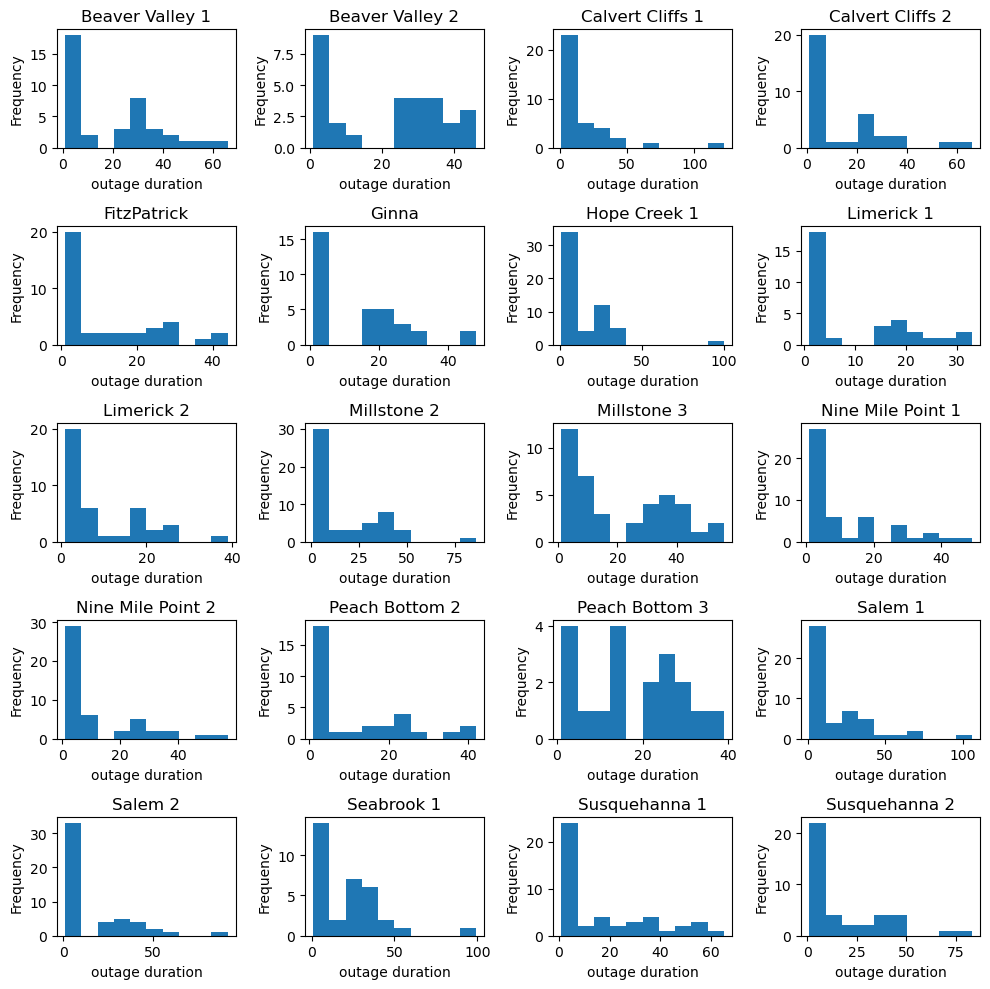

In [22]:
import math

region = "Region 1"

region_outages = outages[outages["Region"] == region]
region_reactors = region_outages["Unit"].unique()

n_plots = len(region_reactors)
n_cols = 4
n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(10,10))
axes = axes.flatten()

for i in range(len(region_reactors)):

    axes[i].hist(region_outages[ region_outages["Unit"] == region_reactors[i] ].Outage_Duration, bins=10)
    axes[i].set_xlabel("outage duration")
    axes[i].set_ylabel("Frequency")
    axes[i].set_title(f'{region_reactors[i]}')

plt.tight_layout()
plt.show()

## Categorizing the outage reasons

Each outage comes with a free-text `Reason` written by the plant operator. To study reliability we need to group these into a handful of categories: **refueling outage**, **maintenance outage**, **planned outage** (planned but not refueling), **unplanned**, **weather related outage**, and **unknown** for reasons that don't say what caused the outage.

In [23]:
outages["Reason"].nunique()

2145

There are 1616 different reasons listed for the output power going down to 0. Let's see a few of them to get a feel for it.

In [24]:
outages["Reason"].value_counts()

Reason
REFUELING OUTAGE                          761
Refueling Outage                          281
MAINTENANCE OUTAGE                        128
ENTERING REFUELING OUTAGE                 114
Maintenance Outage                         62
                                         ... 
SHUTDOWN DUE TO RCS LEAK, SEE EN 52218      1
FORCED OUTAGE\r\nEN 54508                   1
Automatic RX trip. See EN #55416            1
See Event #56005                            1
EN 57284                                    1
Name: count, Length: 2145, dtype: int64

It seems like "REFUELING OUTAGE" and "Refueling outage" are listed as two different reasons. We need some more data cleaning. As can be seen, the refueling and the maintenace outages have been written down in many different ways(`refueling outage`, `entering refueling outage`). 

In [25]:
#.str only works on Pandas Series

outages["Reason"] = outages["Reason"].str.lower()
outages["Reason"] = outages["Reason"].str.strip()

# Replaces one or more whitespace characters in a row to a single space
# some of the reasons fields have ("en \t57285" --> "en 57285")
# Another example is "forced outage\r\nen 54508" --> "forced outage en 54508"
# without regax=true, pandas is literally going to look for \, s and + rather than a pattern

outages["Reason"] = outages["Reason"].str.replace(r"\s+", " ", regex=True)
outages["Reason"].value_counts()

leftover = outages.loc[ ~outages["Reason"].str.contains("refueling outage|maintenance outage") , ["Unit", "Start_Date", "Outage_Duration", "Reason"]]
leftover.to_csv(outdir/"outage_reasons.csv", index=False)


outages[ outages["Reason"] == "refueling outage" ].sample(10)

,Unit,Region,Start_Date,End_Date,Outage_Duration,Reason,Refuel_Days
2625,Quad Cities 2,Region 3,2020-03-30,2020-04-13,15,refueling outage,15
153,Braidwood 1,Region 3,2003-04-15,2003-05-01,17,refueling outage,17
1106,Dresden 3,Region 3,2008-11-03,2008-11-19,17,refueling outage,17
547,Calvert Cliffs 1,Region 1,2014-02-17,2014-03-14,26,refueling outage,26
2948,Salem 2,Region 1,2024-10-06,2024-11-24,50,refueling outage,50
1015,Diablo Canyon 2,Region 4,2008-02-04,2008-04-11,68,refueling outage,58
3185,Surry 1,Region 2,2025-10-12,2025-12-28,78,refueling outage,78
1543,Hope Creek 1,Region 1,2000-04-22,2000-05-22,31,refueling outage,31
1435,Harris 1,Region 2,2018-04-07,2018-05-09,33,refueling outage,33
3512,Vogtle 2,Region 2,2008-09-15,2008-10-19,35,refueling outage,35


Some of the reasons in the table like `shutdown due to rcs leak (reactor collant system)` or `automatic reactor trip` these all fall in the unplanned outages and thus let's classify them as such. So if any reason field contains words like `trip` or `scram` or `leak` or more I will categorize those as unplanned outages

In [26]:
# Creating a new column for the category division

outages["outage_reason"] = outages["Reason"]
outages.head(5)

,Unit,Region,Start_Date,End_Date,Outage_Duration,Reason,Refuel_Days,outage_reason
0,Arkansas Nuclear One 1,Region 4,2000-01-08,2000-01-11,4,shutdown for rcp oil leak repair,0,shutdown for rcp oil leak repair
1,Arkansas Nuclear One 1,Region 4,2000-02-05,2000-03-12,37,shutdown for maintenance outage,0,shutdown for maintenance outage
2,Arkansas Nuclear One 1,Region 4,2000-03-14,2000-03-14,1,manual reactor trip following turbine governor...,0,manual reactor trip following turbine governor...
3,Arkansas Nuclear One 1,Region 4,2001-01-06,2001-01-06,1,manual reactor trip from 80% power due to an e...,0,manual reactor trip from 80% power due to an e...
4,Arkansas Nuclear One 1,Region 4,2001-03-17,2001-04-08,23,refueling outage,23,refueling outage


## GRUNT WORK

In [27]:
# Any kinds of trips or scram or leaks account for unplanned outages, and so do equipment issues, problems and failures
# sometimes there are planned trips as well. Those would be overwritten to planned downstream
mask = outages["Reason"].str.contains("trip|leak|scram|issue|risk|problem|failure|turbine", na=False)

outages.loc[ mask, "outage_reason"] = "unplanned"

# A leak or problem repaired during a maintenance outage is still a maintenance outage
# "maint" also catches the spellings "maint." and "maintainance"
outages.loc[ outages["Reason"].str.contains("maint", na=False), "outage_reason"] = "maintenance outage"

# A trip while shutting down for refueling is still a refueling outage, and so is a refueling outage with maintenance as a side note
# e.g. "scheduled refueling outage the uat will be oos for maintenance"
outages.loc[ outages["Reason"].str.contains("refuel|defuel|fuel load|fueling outage", na=False), "outage_reason"] = "refueling outage"

# There are reasons like "forced maintenance outage", "emergent maintenance outage – stator cooling leak in generator", "shutdown for unplanned maintenance" Even though it has the word maintenace the primary reason is an unplanned outage, so the order here MATTERS 

mask = outages["Reason"].str.contains("forced|unplanned|unscheduled|emergent", na=False)
outages.loc[ mask, "outage_reason"] = "unplanned"

print("After this cleanup we have", outages["outage_reason"].nunique(), "unique reasons for outages")
outages["outage_reason"].value_counts()

After this cleanup we have 523 unique reasons for outages


outage_reason
refueling outage                               1403
unplanned                                      1311
maintenance outage                              475
planned outage                                    7
startup in progress                               3
                                               ... 
tech spec required shutdown - see en #49008       1
tech spec required shutdown. see en #49339        1
tech spec required shutdown. see en #49448.       1
see event #56005                                  1
en 57284                                          1
Name: count, Length: 523, dtype: int64

We can see these `tech spec` reasons listed many times. On further investigation, it was found that Technical Specifications ("tech specs", "TS") are part of every reactor's NRC operating license. They list the safety equipment that must be working while the reactor runs, such as emergency diesel generators, cooling pumps and containment systems. When one of those systems breaks or is declared inoperable, the tech specs give the plant a fixed time to fix it, usually hours to a few days.

Based on this description we will classify those as `unplanned outages`.

Some outages were caused by weather or other natural events: hurricanes, lightning, icing at the cooling water intake and earthquakes. We keep these as their own category, `weather related outage`.

In [28]:
# Operators write tech spec shutdowns in several ways: "tech spec", "technical specification", "ts required", "ts-required", "ts reqd", "ts shutdown", "lco required"
outages.loc[ outages["Reason"].str.contains("tech spec|technical spec|ts required|ts-required|ts reqd|ts shutdown|lco required", na=False), "outage_reason"] = "unplanned"
outages["outage_reason"].value_counts()

outage_reason
refueling outage                                                                                                                     1403
unplanned                                                                                                                            1379
maintenance outage                                                                                                                    471
planned outage                                                                                                                          7
startup in progress                                                                                                                     3
                                                                                                                                     ... 
see en57810                                                                                                                             1
anticipate startup t

Next we will deal with weather related outages. Words like *cold weather alert* or *high wind warning* are **not** used here. These are notices from the grid operator and they show up next to unrelated reasons, e.g. *"refueling outage cold weather alert"*.

In [29]:
# Weather related outages
mask = outages["Reason"].str.contains("hurricane|adverse weather|electrical storm|lightning|lighting strike|icing|earthquake", na=False)
outages.loc[ mask, "outage_reason"] = "weather related outage"
outages["outage_reason"].value_counts()

outage_reason
refueling outage                                                                                                                     1402
unplanned                                                                                                                            1372
maintenance outage                                                                                                                    471
weather related outage                                                                                                                 26
planned outage                                                                                                                          7
                                                                                                                                     ... 
see en57810                                                                                                                             1
anticipate startup t

We have a lot of `see en #` as well. These refer to the reports filed by the reactors to the NRC. Upon further investigation we found out that Under federal rules (10 CFR 50.72), a plant must phone the NRC within hours when something unexpected happens. The NRC gives each report a number and publishes it.

Looking at these two example reports: 

**Example 1: Fermi 2, "See EN #56685" (outage starting 2023-08-21, 18 days): Plant shutdown required by technical specifications**

**Callaway, "See EN# 55049" (outage starting 2020-12-25, 221 days): At 1235 CST on December 24, 2020, Callaway Plant was in Mode 1 at approximately 90 percent power when a turbine trip/reactor trip, from a vital main generator trip signal, occurred.**

As such these ones are also most likely unplanned outages. 

**You have to be a little careful here because a number of refueling and maintenace outages have a report attached as well, so we need to distinguish them.**

In [30]:
# From here on we only label rows that have not been categorized yet, so that we don't overwrite the labels above.
# uncategorized() is recomputed every time it is called, so it always reflects the latest labels.
labels = ["refueling outage", "maintenance outage", "unplanned", "weather related outage", "planned outage", "unknown", "other"]

def uncategorized():
    return ~outages["outage_reason"].isin(labels)

mask = (outages["Reason"].str.contains("see en|see event|en#|en #", na=False) | outages["Reason"].str.contains("en5", na=False) | outages["Reason"].str.contains("en 5", na=False) | outages["Reason"].str.contains("en4", na=False))

outages.loc[ mask & uncategorized(), "outage_reason"] = "unplanned"
outages["outage_reason"].value_counts()

outage_reason
unplanned                                          1671
refueling outage                                   1402
maintenance outage                                  471
weather related outage                               26
planned outage                                        7
                                                   ... 
startup testing                                       1
planned shutdown for midcycle outage                  1
downpower due to main bank transformer concerns       1
starting up.                                          1
anticipate startup this morning                       1
Name: count, Length: 152, dtype: int64

Some outages are planned but are not refueling outages, e.g. *"mid cycle outage"*, *"planned turbine outage"* or *"scheduled turbine outage"*. Note that `planned` is also part of the word `unplanned`, which is one more reason to only apply this to the rows that are still uncategorized. One can also argue that maintenance outages are also planned outages but right now we are treating them as seperate and eventually we can decide if we want to merge them. 

In [31]:
mask = outages["Reason"].str.contains("planned|scheduled|mid cycle|mid-cycle|midcycle", na=False)
outages.loc[ mask & uncategorized(), "outage_reason"] = "planned outage"

leftover = outages.loc[ uncategorized() , ["Unit", "Start_Date", "Outage_Duration", "Reason"]]
leftover.to_csv(outdir/"uncategorized_reasons.csv", index=False)

outages["outage_reason"].value_counts()

outage_reason
unplanned                                          1671
refueling outage                                   1402
maintenance outage                                  471
weather related outage                               26
planned outage                                       25
                                                   ... 
shutdown for testing                                  1
startup testing                                       1
downpower due to main bank transformer concerns       1
starting up.                                          1
anticipate startup this morning                       1
Name: count, Length: 134, dtype: int64

After these steps the remaining reasons are mostly one-offs that appear only once. Looking through them, they fall into four groups, each handled by one cell below. The order matters again: failures are labeled before repairs so that *"due to b rcp seal failure"* becomes unplanned and not maintenance, and the startup notes come last because words like *mode* and *test* also appear in real reasons.

1. **Refueling related states:** *"defueled"*, *"initial fuel load in progress"* and the typo *"fueling outage"*.
2. **Equipment failures and chemistry problems:** *"recirc pump bearing failure"*, *"shutdown due to secondary chemistry"*, *"shutdown due to salp influx at intake"*. These are unplanned.
3. **Shutdowns to repair equipment:** *"shutdown to repair 1b2 reactor coolant pump"*, *"replace 2a recirc pump seal"*. These are the same kind of outage as the *"maintenance outage to repair ..."* reasons, so we label them as maintenance outages.
4. **Startup notes:** *"startup in progress"*, *"increasing power"*, *"power ascension testing"*. These describe the restart and not what caused the outage, so we label them as unknown. Missing reasons and the *"not available"* gap days are unknown as well.

Whatever is left after that is labeled `other`.

In [32]:
# Equipment failures, chemistry problems and things clogging the cooling water intake
mask = outages["Reason"].str.contains("fail|malfunction|lockout|lifted|loss of|loop|dropped rod|misalign|alignment|chemistry|sodium|salp|grassing|intake|fire|required|event|lco", na=False)
outages.loc[ mask & uncategorized(), "outage_reason"] = "unplanned"

In [33]:
# Shutdowns to repair, replace or inspect equipment
mask = outages["Reason"].str.contains("repair|replac|troubleshoot|inspect|seal|valve|pump|generator|transformer|feedwater|heater|rcp|recirc|srv|msiv|ehc|condenser|rod|instrument|detector|work|concern|balance|modification|exciter|cooler|xfmr|mcc|bearing|oil level", na=False)
outages.loc[ mask & uncategorized(), "outage_reason"] = "maintenance outage"

In [34]:

refuel_share = outages["Refuel_Days"] / outages["Outage_Duration"]
mask = (refuel_share >= 0.5)
outages.loc[ mask, "outage_reason" ] = "refueling outage"

# Everything that is left
# Startup / testing notes: these describe the restart, not the cause. Missing reasons and the "not available" gap days are unknown too.
# The ambiguous cold weather alert (with nothing else) is also categorized as unknown

print(outages.loc[ uncategorized(), ["Reason", "Outage_Duration"] ].value_counts())
outages.loc[ uncategorized(), "outage_reason"] = "unknown"

outages["outage_reason"].value_counts()

Reason                                                       Outage_Duration
startup in progress                                          1                  2
increasing power                                             2                  1
startup in progress                                          3                  1
not available                                                5                  1
preparing for startup                                        1                  1
preparations for startup                                     1                  1
shutdown due to clogged screens.                             2                  1
cold weather alert                                           2                  1
increasing power per power ascension plan                    1                  1
proceeding to cold shutdown                                  3                  1
reactor startup in progress                                  1                  1
insufficient number o

outage_reason
unplanned                 1644
refueling outage          1456
maintenance outage         552
unknown                     34
weather related outage      24
planned outage              22
Name: count, dtype: int64

### Result

Every outage now has one of the categories. The table shows the number of outages, the median duration in days, the total number of outage days and the share of all outage days for each category. Refueling outages are few but long (median of about a month) and make up most of the outage days, while unplanned and maintenance outages typically last only a few days.

In [35]:
# count only counts the number of rows but sum would sum up the numbers in the outage_duration
summary = outages.groupby("outage_reason")["Outage_Duration"].agg(["count", "median", "sum"]).sort_values("count", ascending=False)
summary["percent_of_outage_days"] = (100 * summary["sum"] / summary["sum"].sum()).round(1)

print("Number of categories:", outages["outage_reason"].nunique())
summary

Number of categories: 6


,count,median,sum,percent_of_outage_days
outage_reason,,,,
unplanned,1644,3.0,10121,14.0
refueling outage,1456,33.0,57929,80.0
maintenance outage,552,5.0,3774,5.2
unknown,34,1.0,94,0.1
weather related outage,24,7.0,278,0.4
planned outage,22,7.5,234,0.3


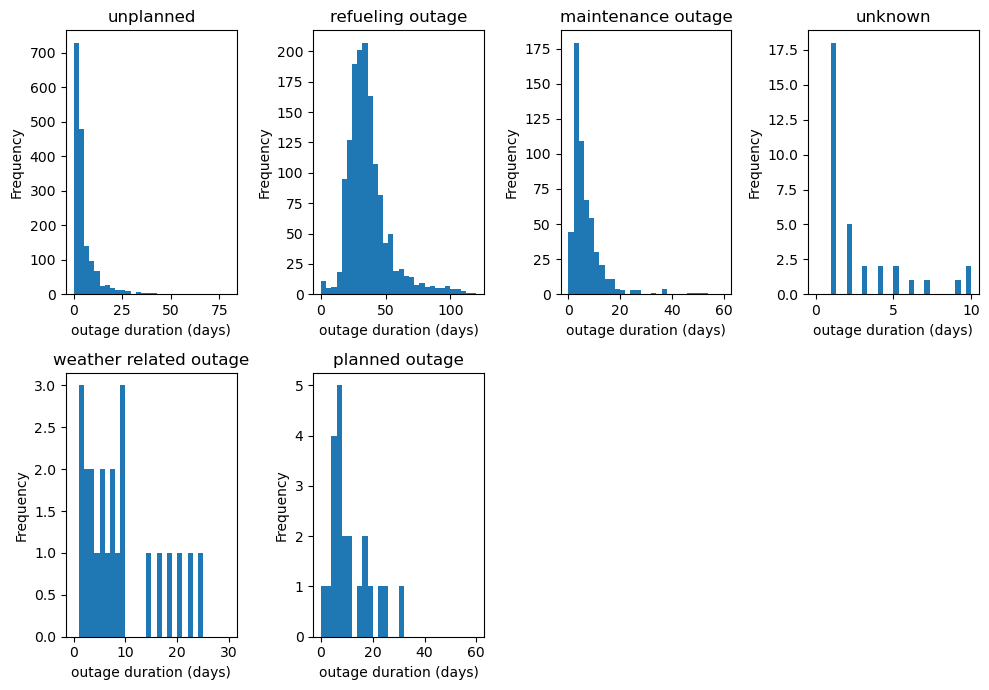

In [36]:
categories = summary.index

x_limits = {"unplanned": 80, "refueling outage": 120, "maintenance outage": 60, "planned outage": 60, "weather related outage": 30, "unknown": 10}

fig, axes = plt.subplots(2, 4, figsize=(10,7))
axes = axes.flatten()

for i in range(len(categories)):

    limit = x_limits[categories[i]]
    axes[i].hist(outages[ outages["outage_reason"] == categories[i] ].Outage_Duration, bins=30, range=(0, limit))
    axes[i].set_xlabel("outage duration (days)")
    axes[i].set_ylabel("Frequency")
    axes[i].set_title(f'{categories[i]}')

# Hide the empty plots
for j in range(len(categories), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [37]:
outages[ outages["outage_reason"] == "unknown" ].Reason

145                                      increasing power
483                                   startup in progress
578                                         not available
697                                 preparing for startup
915                              preparations for startup
1008                     shutdown due to clogged screens.
1071                                   cold weather alert
1197            increasing power per power ascension plan
1258                          proceeding to cold shutdown
1264                                  startup in progress
1441                          reactor startup in progress
1469           insufficient number of irms during startup
1513                     startup preparations in progress
1549                             rcs cooldown in progress
1726                                     increasing power
1805                    making preparation for rx startup
1814                   start-up surveillances in progress
2021          

As can be seen, the "not avialable" mark that we used for the missing days is only appearing once so it's not a huge problem.

Also from the outage duration dstribution of the various outage reasons, its fair to assume that merging maintenance and planned outages would not be a bad idea.

In [38]:
outages["outage_reason"] = outages["outage_reason"].replace({ "planned outage": "planned/maintenance outage", "maintenance outage":"planned/maintenance outage" })

In [39]:
outages["outage_reason"].value_counts()
summary = outages.groupby("outage_reason")["Outage_Duration"].agg(["count", "median", "sum"])
summary["percent_days"] = 100*(summary["sum"]/(summary["sum"].sum()))
summary

,count,median,sum,percent_days
outage_reason,,,,
planned/maintenance outage,574,5.0,4008,5.533619
refueling outage,1456,33.0,57929,79.979290
unknown,34,1.0,94,0.129780
unplanned,1644,3.0,10121,13.973492
weather related outage,24,7.0,278,0.383819


<ArrowStringArray>
[                 'unplanned', 'planned/maintenance outage',
           'refueling outage',                    'unknown',
     'weather related outage']
Length: 5, dtype: str


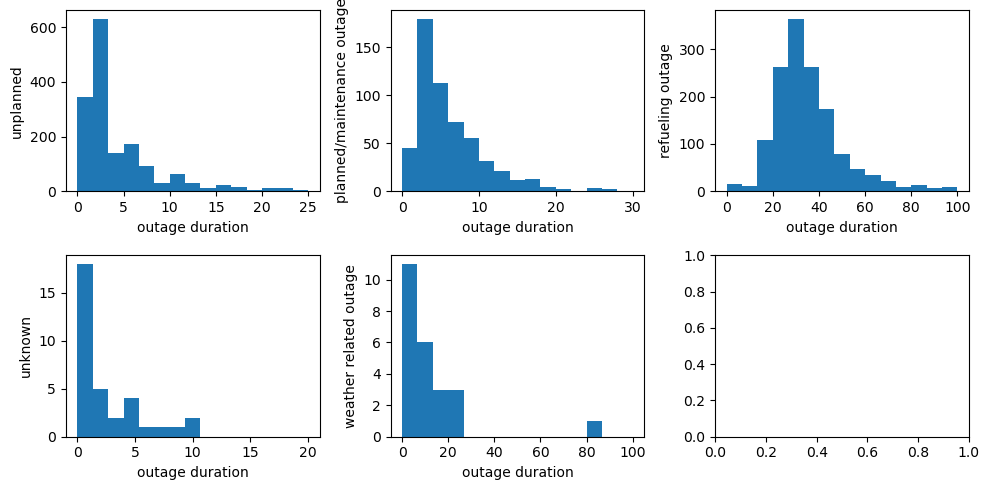

In [40]:
reasons = outages["outage_reason"].unique()
print(reasons)

limit = { "refueling outage":100, "unplanned":25, "planned/maintenance outage":30,  "unknown": 20, "weather related outage": 100}

fig, axes = plt.subplots(2,3,figsize=(10,5))
axes = axes.flatten()

for i in range(len(reasons)):
    axes[i].hist(outages[ outages["outage_reason"] == reasons[i] ].Outage_Duration, bins=15, range=(0, limit[reasons[i]]) )
    axes[i].set_xlabel("outage duration")
    axes[i].set_ylabel(reasons[i])

plt.tight_layout()
plt.show()

In [41]:
outages.head(10)

,Unit,Region,Start_Date,End_Date,Outage_Duration,Reason,Refuel_Days,outage_reason
0,Arkansas Nuclear One 1,Region 4,2000-01-08,2000-01-11,4,shutdown for rcp oil leak repair,0,unplanned
1,Arkansas Nuclear One 1,Region 4,2000-02-05,2000-03-12,37,shutdown for maintenance outage,0,planned/maintenance outage
2,Arkansas Nuclear One 1,Region 4,2000-03-14,2000-03-14,1,manual reactor trip following turbine governor...,0,unplanned
3,Arkansas Nuclear One 1,Region 4,2001-01-06,2001-01-06,1,manual reactor trip from 80% power due to an e...,0,unplanned
4,Arkansas Nuclear One 1,Region 4,2001-03-17,2001-04-08,23,refueling outage,23,refueling outage
5,Arkansas Nuclear One 1,Region 4,2001-07-25,2001-07-25,1,reactor trip on high rcs pressure. plant prepa...,0,unplanned
6,Arkansas Nuclear One 1,Region 4,2002-10-05,2002-11-12,39,preparing for refueling outage,38,refueling outage
7,Arkansas Nuclear One 1,Region 4,2003-08-30,2003-08-30,1,automatic reactor trip - see event #40119,0,unplanned
8,Arkansas Nuclear One 1,Region 4,2003-11-16,2003-12-10,25,main xfmr repairs,0,planned/maintenance outage
9,Arkansas Nuclear One 1,Region 4,2004-04-21,2004-05-12,22,refueling outage,22,refueling outage


One useful thing to look at could be the power a few days before an outage started. We can build a column for that in our `Outages` dataframe.

In [42]:
by_unit = {unit: df for unit, df in new_df.groupby("Unit")}

power_1d_before=[]

for unit, start_date in zip(outages["Unit"], outages["Start_Date"]):

    unit_df = by_unit[unit]
    mask = (unit_df["date"] >= start_date - pd.Timedelta(days=1)) & (unit_df["date"] < start_date)
    power_1d_before.append(unit_df.loc[mask, "Power"].mean()) 

outages["power_1d_before"] = power_1d_before

outages[["Unit", "Region", "Start_Date", "End_Date", "Outage_Duration", "outage_reason"]].to_csv(outdir/"outages_data.csv", sep="\t", index=False)

outages.head(10)

,Unit,Region,Start_Date,End_Date,Outage_Duration,Reason,Refuel_Days,outage_reason,power_1d_before
0,Arkansas Nuclear One 1,Region 4,2000-01-08,2000-01-11,4,shutdown for rcp oil leak repair,0,unplanned,100.0
1,Arkansas Nuclear One 1,Region 4,2000-02-05,2000-03-12,37,shutdown for maintenance outage,0,planned/maintenance outage,72.0
2,Arkansas Nuclear One 1,Region 4,2000-03-14,2000-03-14,1,manual reactor trip following turbine governor...,0,unplanned,12.0
3,Arkansas Nuclear One 1,Region 4,2001-01-06,2001-01-06,1,manual reactor trip from 80% power due to an e...,0,unplanned,100.0
4,Arkansas Nuclear One 1,Region 4,2001-03-17,2001-04-08,23,refueling outage,23,refueling outage,98.0
5,Arkansas Nuclear One 1,Region 4,2001-07-25,2001-07-25,1,reactor trip on high rcs pressure. plant prepa...,0,unplanned,100.0
6,Arkansas Nuclear One 1,Region 4,2002-10-05,2002-11-12,39,preparing for refueling outage,38,refueling outage,72.0
7,Arkansas Nuclear One 1,Region 4,2003-08-30,2003-08-30,1,automatic reactor trip - see event #40119,0,unplanned,100.0
8,Arkansas Nuclear One 1,Region 4,2003-11-16,2003-12-10,25,main xfmr repairs,0,planned/maintenance outage,35.0
9,Arkansas Nuclear One 1,Region 4,2004-04-21,2004-05-12,22,refueling outage,22,refueling outage,99.0


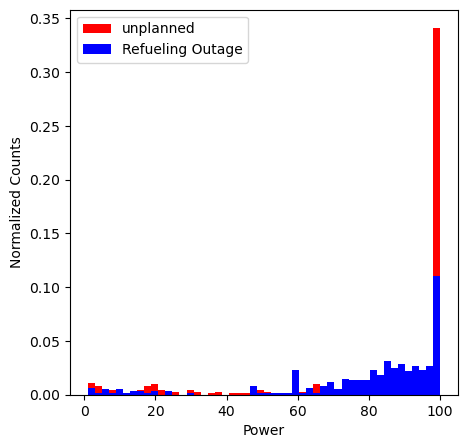

In [43]:
mask1 = (outages["outage_reason"] == "unplanned") & (outages["Region"] == "Region 1")
mask2 = (outages["outage_reason"] == "refueling outage") & (outages["Region"] == "Region 1")
plt.figure(figsize=(5,5))
plt.hist(outages[mask1].power_1d_before, bins=50, density=True, color="red", label="unplanned")
plt.hist(outages[mask2].power_1d_before, bins=50, density=True, color="blue", label="Refueling Outage")
plt.xlabel("Power")
plt.ylabel("Normalized Counts")
plt.legend()
plt.show()

Okay so it seems like the power one day before an outage is mostly off from 100% for the refueling outages and for the unplanned outages they are more sudden and the corresponding power the past day is not that different from 100%